AI Resume Analyzer and Job Recommendation System

Project Overview

This project aims to develop an NLP-based application that analyzes resumes and recommends suitable job roles based on the skills identified in the resume.

Objectives

Extract text from PDF and DOCX resumes.

Clean and preprocess resume text.

Identify technical and job-related skills.

Compare resumes against multiple job-role requirements.

Calculate match scores and recommend suitable roles.

Identify missing skills and generate a learning roadmap.

Develop a Streamlit dashboard to display the results.

Technologies Used

Python, Google Colab, Pandas, Scikit-learn, pypdf, python-docx, and Streamlit.

Methodology

Resume Upload → Text Extraction → Text Cleaning → Skill Extraction → Job Matching → Skill-Gap Analysis → Job Recommendations → Learning Roadmap.

Expected Outcome

A working resume analysis system that provides estimated job-role match scores, identifies skill gaps, and recommends learning topics.


In [1]:

!pip -q install pypdf python-docx pandas numpy scikit-learn matplotlib seaborn streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 73.7 MB/s eta 0:00:00


In [2]:

import re
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pypdf import PdfReader
from docx import Document

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("All required libraries imported successfully!")


All required libraries imported successfully!


## Job Role Dataset

In [3]:

import pandas as pd

job_roles = {
    "Data Analyst": [
        "Python", "SQL", "Excel", "Pandas", "NumPy", "Power BI"
    ],
    "Machine Learning Engineer": [
        "Python", "Machine Learning", "Scikit-learn",
        "Pandas", "NumPy", "FastAPI", "Docker"
    ],
    "AI Engineer": [
        "Python", "Deep Learning", "NLP", "TensorFlow",
        "PyTorch", "APIs", "LLM"
    ],
    "Web Developer": [
        "HTML", "CSS", "JavaScript", "React",
        "Node.js", "SQL", "Git"
    ],
    "NLP Engineer": [
        "Python", "NLP", "Transformers", "Hugging Face",
        "Machine Learning", "PyTorch"
    ],
    "Computer Vision Engineer": [
        "Python", "OpenCV", "CNN", "Deep Learning",
        "TensorFlow", "PyTorch"
    ]
}

job_data = []

for role, skills in job_roles.items():
    job_data.append({
        "Job_Role": role,
        "Required_Skills": ", ".join(skills),
        "Number_of_Skills": len(skills)
    })

job_df = pd.DataFrame(job_data)

print("Job-role dataset created successfully!")
display(job_df)


Job-role dataset created successfully!


,Job_Role,Required_Skills,Number_of_Skills
0,Data Analyst,"Python, SQL, Excel, Pandas, NumPy, Power BI",6
1,Machine Learning Engineer,"Python, Machine Learning, Scikit-learn, Pandas...",7
2,AI Engineer,"Python, Deep Learning, NLP, TensorFlow, PyTorc...",7
3,Web Developer,"HTML, CSS, JavaScript, React, Node.js, SQL, Git",7
4,NLP Engineer,"Python, NLP, Transformers, Hugging Face, Machi...",6
5,Computer Vision Engineer,"Python, OpenCV, CNN, Deep Learning, TensorFlow...",6


In [4]:

skill_dictionary = {
    "Programming": [
        "Python", "Java", "C", "C++", "JavaScript",
        "HTML", "CSS", "R"
    ],
    "Databases": [
        "SQL", "MySQL", "PostgreSQL", "MongoDB"
    ],
    "Data Science": [
        "Pandas", "NumPy", "Excel", "Power BI",
        "Matplotlib", "Statistics", "Data Analysis"
    ],
    "Machine Learning and AI": [
        "Machine Learning", "Deep Learning",
        "Scikit-learn", "TensorFlow", "PyTorch",
        "NLP", "LLM", "Transformers",
        "Hugging Face", "OpenCV", "CNN"
    ],
    "Web and Deployment": [
        "React", "Node.js", "Flask", "FastAPI",
        "REST API", "Docker", "Git", "GitHub",
        "AWS", "Azure", "Streamlit", "Linux"
    ]
}

skill_rows = []

for category, skills in skill_dictionary.items():
    for skill in skills:
        skill_rows.append({
            "Category": category,
            "Skill": skill
        })

skill_df = pd.DataFrame(skill_rows)

print("Total skills:", len(skill_df))
display(skill_df)


Total skills: 42


,Category,Skill
0,Programming,Python
1,Programming,Java
2,Programming,C
3,Programming,C++
4,Programming,JavaScript
5,Programming,HTML
6,Programming,CSS
7,Programming,R
8,Databases,SQL
9,Databases,MySQL


In [5]:

import os

os.makedirs("data", exist_ok=True)

job_df.to_csv("data/job_roles.csv", index=False)
skill_df.to_csv("data/skill_dictionary.csv", index=False)

print("Datasets saved successfully!")
print("1. data/job_roles.csv")
print("2. data/skill_dictionary.csv")


Datasets saved successfully!
1. data/job_roles.csv
2. data/skill_dictionary.csv


In [6]:

from google.colab import files

files.download("data/job_roles.csv")
files.download("data/skill_dictionary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 3: Resume Parsing

In this module, the system accepts PDF and DOCX resume files and extracts their textual content. The extracted text is used as input for text preprocessing, skill extraction, and job-role matching.

In [7]:

from pypdf import PdfReader

def extract_text_from_pdf(file_path):
    """Extract text from all pages of a PDF resume."""
    reader = PdfReader(file_path)
    text = ""

    for page in reader.pages:
        page_text = page.extract_text()
        if page_text:
            text += page_text + "\n"

    return text

print("PDF extraction function created successfully!")


PDF extraction function created successfully!


In [8]:

from docx import Document

def extract_text_from_docx(file_path):
    """Extract text from paragraphs and tables in a DOCX resume."""
    document = Document(file_path)
    text_parts = []

    # Extract paragraph text
    for paragraph in document.paragraphs:
        if paragraph.text.strip():
            text_parts.append(paragraph.text)

    # Extract text from tables
    for table in document.tables:
        for row in table.rows:
            for cell in row.cells:
                if cell.text.strip():
                    text_parts.append(cell.text)

    return "\n".join(text_parts)

print("DOCX extraction function created successfully!")


DOCX extraction function created successfully!


In [9]:

def extract_resume_text(file_path):
    """Extract text based on the resume file extension."""
    extension = file_path.lower().rsplit(".", 1)[-1]

    if extension == "pdf":
        return extract_text_from_pdf(file_path)

    elif extension == "docx":
        return extract_text_from_docx(file_path)

    else:
        raise ValueError("Unsupported file format. Upload PDF or DOCX.")

print("Resume parser is ready!")


Resume parser is ready!


In [10]:

from docx import Document

sample_doc = Document()
sample_doc.add_heading("Sample Resume", 0)
sample_doc.add_paragraph("Name: Sample Candidate")
sample_doc.add_heading("Skills", level=1)
sample_doc.add_paragraph(
    "Python, SQL, Pandas, NumPy, Machine Learning, "
    "Scikit-learn, Power BI, Git, and Streamlit."
)
sample_doc.add_heading("Projects", level=1)
sample_doc.add_paragraph(
    "Developed a machine learning model for prediction "
    "and created a Streamlit dashboard."
)
sample_doc.save("sample_resume.docx")

print("Sample resume created!")


Sample resume created!


In [11]:

extracted_text = extract_resume_text("sample_resume.docx")

print("Extracted Resume Text:")
print("-" * 40)
print(extracted_text)

assert "Python" in extracted_text
assert "Machine Learning" in extracted_text

print("\nResume extraction test passed!")


Extracted Resume Text:
----------------------------------------
Sample Resume
Name: Sample Candidate
Skills
Python, SQL, Pandas, NumPy, Machine Learning, Scikit-learn, Power BI, Git, and Streamlit.
Projects
Developed a machine learning model for prediction and created a Streamlit dashboard.

Resume extraction test passed!


In [12]:

from google.colab import files

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    resume_text = extract_resume_text(filename)

    print("Uploaded file:", filename)
    print("\nExtracted text preview:\n")
    print(resume_text[:3000])

    if not resume_text.strip():
        print("No text found. The PDF may be scanned or image-based.")


Saving Avanti Kangutkar_Infosys.pdf to Avanti Kangutkar_Infosys.pdf
Uploaded file: Avanti Kangutkar_Infosys.pdf

Extracted text preview:

Avanti Kangutkar 
Phone: +91-7892066385 | Email: avantikangutkar99@gmail.com| Belgaum, Karnataka | LinkedIn: linkedin.com/in/avantikangutkar 
Career Objective 
 
Computer Science undergraduate with hands-on experience in computer vision and applied machine learning, including real-time video 
analytics using OpenCV, MediaPipe , and YOLO. Proficient in data structures, algorithms, and software engineering, with experience 
shipping functional systems in team -based projects. Seeking to build applied AI and media technology solutions in a fast -paced 
engineering team. 
 
Education  
Examination University/Board Institute Year CGPA / % 
 
B.E (CSE) VTU Belagavi KLS Gogte Institute of Technology 2027             9.54  
Class XII Karnataka DPUE GSS Science College, Belagavi 2023 97.50%  
Class X State Board Divine Providence Convent High School 2021 99.0

## Step 4: Text Cleaning and Skill Extraction

This module cleans extracted resume text and identifies job-related skills using a predefined skill dictionary. The detected skills will be used for job-role matching and skill-gap analysis.

In [13]:

import re

def clean_resume_text(text):
    """Normalize resume text while preserving useful technical symbols."""
    text = text.lower()

    # Normalize common technical terms
    text = text.replace("scikit learn", "scikit-learn")
    text = text.replace("node js", "node.js")
    text = text.replace("power bi", "power bi")

    # Remove email addresses and URLs
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

cleaned_text = clean_resume_text(extracted_text)

print("Original text length:", len(extracted_text))
print("Cleaned text length:", len(cleaned_text))
print("\nCleaned text preview:\n", cleaned_text[:1000])


Original text length: 227
Cleaned text length: 227

Cleaned text preview:
 sample resume name: sample candidate skills python, sql, pandas, numpy, machine learning, scikit-learn, power bi, git, and streamlit. projects developed a machine learning model for prediction and created a streamlit dashboard.


In [14]:

all_skills = [
    skill
    for category, skills in skill_dictionary.items()
    for skill in skills
]

print("Total skills available:", len(all_skills))
print(all_skills)


Total skills available: 42
['Python', 'Java', 'C', 'C++', 'JavaScript', 'HTML', 'CSS', 'R', 'SQL', 'MySQL', 'PostgreSQL', 'MongoDB', 'Pandas', 'NumPy', 'Excel', 'Power BI', 'Matplotlib', 'Statistics', 'Data Analysis', 'Machine Learning', 'Deep Learning', 'Scikit-learn', 'TensorFlow', 'PyTorch', 'NLP', 'LLM', 'Transformers', 'Hugging Face', 'OpenCV', 'CNN', 'React', 'Node.js', 'Flask', 'FastAPI', 'REST API', 'Docker', 'Git', 'GitHub', 'AWS', 'Azure', 'Streamlit', 'Linux']


In [15]:

def extract_skills(text, skills_list):
    """Identify skills using case-insensitive, boundary-aware matching."""
    detected_skills = []

    for skill in skills_list:
        pattern = r'(?<!\w)' + re.escape(skill.lower()) + r'(?!\w)'

        if re.search(pattern, text.lower()):
            detected_skills.append(skill)

    return sorted(set(detected_skills), key=str.lower)

detected_skills = extract_skills(cleaned_text, all_skills)

print("Skills identified in the resume:")
for skill in detected_skills:
    print("-", skill)

print("\nTotal skills detected:", len(detected_skills))


Skills identified in the resume:
- Git
- Machine Learning
- NumPy
- Pandas
- Power BI
- Python
- Scikit-learn
- SQL
- Streamlit

Total skills detected: 9


In [16]:

test_resume = """
Experienced Python developer with SQL, Pandas and NumPy.
Worked on a Machine Learning project using Scikit-learn.
Built a dashboard using Power BI and Streamlit.
"""

test_cleaned = clean_resume_text(test_resume)
test_skills = extract_skills(test_cleaned, all_skills)

print("Detected test skills:", test_skills)

assert "Python" in test_skills
assert "SQL" in test_skills
assert "Pandas" in test_skills
assert "Machine Learning" in test_skills
assert "Power BI" in test_skills
assert "Docker" not in test_skills

print("\nAll skill extraction tests passed!")


Detected test skills: ['Machine Learning', 'NumPy', 'Pandas', 'Power BI', 'Python', 'Scikit-learn', 'SQL', 'Streamlit']

All skill extraction tests passed!


In [17]:

detected_set = {skill.lower() for skill in detected_skills}

for category, skills in skill_dictionary.items():
    found = [
        skill for skill in skills
        if skill.lower() in detected_set
    ]

    if found:
        print(f"\n{category}:")
        print(", ".join(found))



Programming:
Python

Databases:
SQL

Data Science:
Pandas, NumPy, Power BI

Machine Learning and AI:
Machine Learning, Scikit-learn

Web and Deployment:
Git, Streamlit


## Step 5: Job Matching and Recommendation

This module compares the cleaned resume with predefined job-role requirements using TF-IDF vectorization and cosine similarity. It also calculates skill coverage for each role and ranks the roles to recommend the top three.

In [18]:

# Convert the job-role dataset into a dictionary
job_requirements = {}

for _, row in job_df.iterrows():
    job_requirements[row["Job_Role"]] = [
        skill.strip()
        for skill in row["Required_Skills"].split(",")
    ]

print("Available job roles:")
for role in job_requirements:
    print("-", role)


Available job roles:
- Data Analyst
- Machine Learning Engineer
- AI Engineer
- Web Developer
- NLP Engineer
- Computer Vision Engineer


In [19]:

# Prepare the resume and job-role texts
roles = list(job_requirements.keys())

role_texts = [
    " ".join(job_requirements[role])
    for role in roles
]

documents = [cleaned_text] + role_texts

# Convert the documents into TF-IDF vectors
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

tfidf_matrix = vectorizer.fit_transform(documents)

# Compare the resume vector with every role vector
similarity_scores = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:]
).flatten()

print("TF-IDF similarity calculated successfully!")


TF-IDF similarity calculated successfully!


In [20]:

# Normalize detected skills for comparison
detected_skill_set = {
    skill.lower() for skill in detected_skills
}

results = []

for index, role in enumerate(roles):
    required_skills = job_requirements[role]

    matched_skills = [
        skill for skill in required_skills
        if skill.lower() in detected_skill_set
    ]

    missing_skills = [
        skill for skill in required_skills
        if skill.lower() not in detected_skill_set
    ]

    coverage_score = (
        len(matched_skills) / len(required_skills) * 100
        if required_skills else 0
    )

    similarity_score = similarity_scores[index] * 100

    results.append({
        "Job_Role": role,
        "Similarity_Score": round(similarity_score, 2),
        "Skill_Coverage": round(coverage_score, 2),
        "Matched_Skills": ", ".join(matched_skills),
        "Missing_Skills": ", ".join(missing_skills)
    })

results_df = pd.DataFrame(results)

# Rank roles using skill coverage as the primary ranking metric
results_df = results_df.sort_values(
    by=["Skill_Coverage", "Similarity_Score"],
    ascending=False
).reset_index(drop=True)

results_df.insert(
    0, "Rank", range(1, len(results_df) + 1)
)

display(results_df)


,Rank,Job_Role,Similarity_Score,Skill_Coverage,Matched_Skills,Missing_Skills
0,1,Data Analyst,21.75,83.33,"Python, SQL, Pandas, NumPy, Power BI",Excel
1,2,Machine Learning Engineer,26.96,71.43,"Python, Machine Learning, Scikit-learn, Pandas...","FastAPI, Docker"
2,3,NLP Engineer,10.77,33.33,"Python, Machine Learning","NLP, Transformers, Hugging Face, PyTorch"
3,4,Web Developer,4.13,28.57,"SQL, Git","HTML, CSS, JavaScript, React, Node.js"
4,5,Computer Vision Engineer,3.37,16.67,Python,"OpenCV, CNN, Deep Learning, TensorFlow, PyTorch"
5,6,AI Engineer,3.12,14.29,Python,"Deep Learning, NLP, TensorFlow, PyTorch, APIs,..."


In [21]:

top_three = results_df.head(3)

print("TOP 3 RECOMMENDED JOB ROLES")
print("=" * 40)

for _, row in top_three.iterrows():
    print(f"\nRank {row['Rank']}: {row['Job_Role']}")
    print(f"Skill Coverage: {row['Skill_Coverage']}%")
    print(f"Text Similarity: {row['Similarity_Score']}%")
    print(f"Matched Skills: {row['Matched_Skills']}")


TOP 3 RECOMMENDED JOB ROLES

Rank 1: Data Analyst
Skill Coverage: 83.33%
Text Similarity: 21.75%
Matched Skills: Python, SQL, Pandas, NumPy, Power BI

Rank 2: Machine Learning Engineer
Skill Coverage: 71.43%
Text Similarity: 26.96%
Matched Skills: Python, Machine Learning, Scikit-learn, Pandas, NumPy

Rank 3: NLP Engineer
Skill Coverage: 33.33%
Text Similarity: 10.77%
Matched Skills: Python, Machine Learning


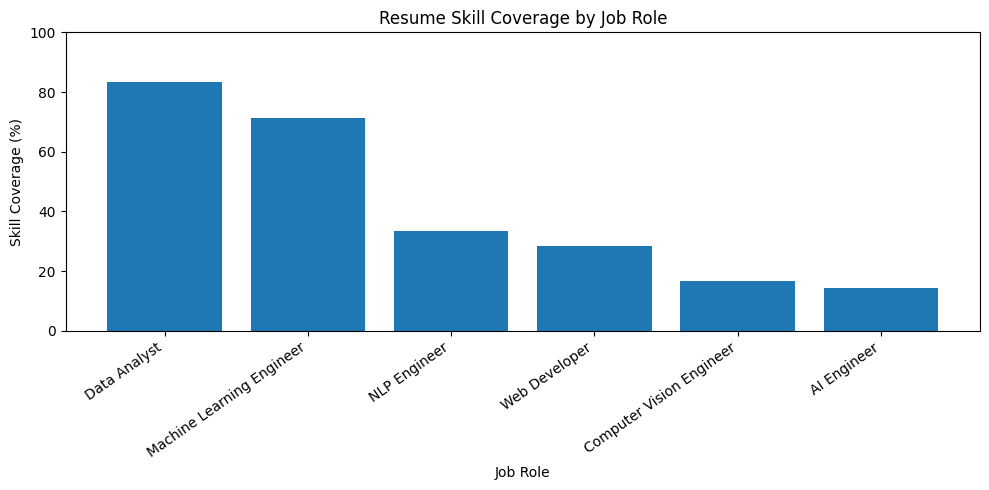

In [22]:

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Job_Role"],
    results_df["Skill_Coverage"]
)

plt.title("Resume Skill Coverage by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Skill Coverage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## Step 6: Skill-Gap Analysis and Learning Roadmap.

In [23]:

def analyze_skill_gap(role, detected_skills, job_requirements):
    """Compare detected resume skills with role requirements."""

    if role not in job_requirements:
        raise ValueError("Please select a valid job role.")

    required = job_requirements[role]

    detected = {skill.lower() for skill in detected_skills}

    matched = [
        skill for skill in required
        if skill.lower() in detected
    ]

    missing = [
        skill for skill in required
        if skill.lower() not in detected
    ]

    coverage = (
        len(matched) / len(required) * 100
        if required else 0
    )

    return {
        "role": role,
        "matched_skills": matched,
        "missing_skills": missing,
        "coverage": round(coverage, 2)
    }


print("Skill-gap analysis function created successfully!")


Skill-gap analysis function created successfully!


In [26]:

print("Available job roles:")
for i, role in enumerate(job_requirements.keys(), start=1):
    print(f"{i}. {role}")

target_role = input(
    "\nEnter your target job role: "
).strip().rstrip(".")

if target_role not in job_requirements:
    print("Invalid role. Please select a role from the list.")
else:
    gap_report = analyze_skill_gap(
        target_role,
        detected_skills,
        job_requirements
    )

    print("\nTARGET ROLE:", gap_report["role"])
    print("SKILL COVERAGE:", str(gap_report["coverage"]) + "%")

    print("\nSKILLS FOUND:")
    print(gap_report["matched_skills"] or "None detected")

    print("\nSKILLS TO LEARN:")
    print(
        gap_report["missing_skills"]
        or "No listed skill gaps detected"
    )


Available job roles:
1. Data Analyst
2. Machine Learning Engineer
3. AI Engineer
4. Web Developer
5. NLP Engineer
6. Computer Vision Engineer

Enter your target job role: Machine Learning Engineer

TARGET ROLE: Machine Learning Engineer
SKILL COVERAGE: 71.43%

SKILLS FOUND:
['Python', 'Machine Learning', 'Scikit-learn', 'Pandas', 'NumPy']

SKILLS TO LEARN:
['FastAPI', 'Docker']


In [27]:

learning_resources = {
    "Python": "Python fundamentals, functions, and data structures",
    "SQL": "SQL queries, joins, grouping, and subqueries",
    "Excel": "Formulas, pivot tables, and data cleaning",
    "Pandas": "DataFrames, filtering, and data manipulation",
    "NumPy": "Arrays, indexing, and numerical operations",
    "Power BI": "Data modeling, dashboards, and DAX basics",
    "Machine Learning": "Supervised learning and model evaluation",
    "Scikit-learn": "Preprocessing, model training, and evaluation",
    "FastAPI": "Build and test a Python REST API",
    "Docker": "Docker images, containers, and Dockerfiles",
    "Deep Learning": "Neural networks and backpropagation",
    "TensorFlow": "Build and train a basic neural network",
    "PyTorch": "Tensors, datasets, and model training",
    "NLP": "Text preprocessing and text classification",
    "LLM": "Large language model concepts and applications",
    "APIs": "HTTP methods, requests, and API integration",
    "Transformers": "Transformer architecture and attention",
    "Hugging Face": "Pretrained models and tokenizers",
    "OpenCV": "Image processing and filtering",
    "CNN": "Convolutional layers and image classification",
    "HTML": "Semantic HTML and accessible page structure",
    "CSS": "Flexbox, Grid, and responsive styling",
    "JavaScript": "DOM manipulation and asynchronous code",
    "React": "Components, props, state, and hooks",
    "Node.js": "Server-side JavaScript and backend fundamentals",
    "Git": "Version control, branches, and commits"
}

def generate_roadmap(missing_skills):
    roadmap = []

    for index, skill in enumerate(missing_skills, start=1):
        topic = learning_resources.get(
            skill,
            f"Learn the fundamentals and practical use of {skill}"
        )

        roadmap.append({
            "Week": index,
            "Skill": skill,
            "Learning_Plan": topic
        })

    return pd.DataFrame(roadmap)

roadmap_df = generate_roadmap(gap_report["missing_skills"])

if roadmap_df.empty:
    print("No listed skill gaps detected.")
    print("Consider building an advanced project.")
else:
    print("PERSONALIZED LEARNING ROADMAP")
    display(roadmap_df)


PERSONALIZED LEARNING ROADMAP


,Week,Skill,Learning_Plan
0,1,FastAPI,Build and test a Python REST API
1,2,Docker,"Docker images, containers, and Dockerfiles"


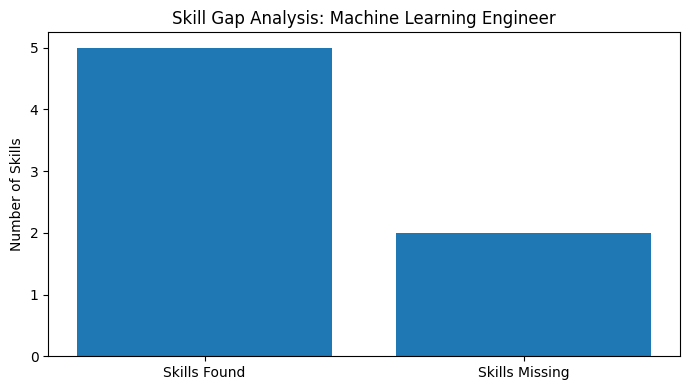

Skill coverage: 71.43%


In [28]:

matched_count = len(gap_report["matched_skills"])
missing_count = len(gap_report["missing_skills"])

plt.figure(figsize=(7, 4))
plt.bar(
    ["Skills Found", "Skills Missing"],
    [matched_count, missing_count]
)
plt.title(f"Skill Gap Analysis: {gap_report['role']}")
plt.ylabel("Number of Skills")
plt.tight_layout()
plt.show()

print(f"Skill coverage: {gap_report['coverage']}%")


In [29]:

os.makedirs("reports", exist_ok=True)

gap_df = pd.DataFrame(
    [{"Skill": skill, "Status": "Found"}
     for skill in gap_report["matched_skills"]]
    +
    [{"Skill": skill, "Status": "Missing"}
     for skill in gap_report["missing_skills"]]
)

gap_df.to_csv("reports/skill_gap_report.csv", index=False)
roadmap_df.to_csv("reports/learning_roadmap.csv", index=False)

print("Reports saved successfully!")
print("reports/skill_gap_report.csv")
print("reports/learning_roadmap.csv")


Reports saved successfully!
reports/skill_gap_report.csv
reports/learning_roadmap.csv


In [30]:

def analyze_resume(file_path):
    # 1. Extract resume text
    raw_text = extract_resume_text(file_path)

    if not raw_text.strip():
        raise ValueError(
            "No readable text found. Please upload a text-based PDF or DOCX."
        )

    # 2. Clean resume text
    cleaned_text = clean_resume_text(raw_text)

    # 3. Extract skills
    detected_skills = extract_skills(cleaned_text, all_skills)

    # 4. Compare resume with job roles
    role_texts = [
        " ".join(job_requirements[role])
        for role in job_requirements
    ]

    documents = [cleaned_text] + role_texts

    vectorizer = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2)
    )
    tfidf_matrix = vectorizer.fit_transform(documents)

    similarity_scores = cosine_similarity(
        tfidf_matrix[0:1],
        tfidf_matrix[1:]
    ).flatten()

    detected_set = {skill.lower() for skill in detected_skills}
    results = []

    for index, role in enumerate(job_requirements):
        required = job_requirements[role]

        matched = [
            skill for skill in required
            if skill.lower() in detected_set
        ]

        missing = [
            skill for skill in required
            if skill.lower() not in detected_set
        ]

        coverage = (
            len(matched) / len(required) * 100
            if required else 0
        )

        results.append({
            "Job_Role": role,
            "Similarity_Score": round(
                similarity_scores[index] * 100, 2
            ),
            "Skill_Coverage": round(coverage, 2),
            "Matched_Skills": ", ".join(matched),
            "Missing_Skills": ", ".join(missing)
        })

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by=["Skill_Coverage", "Similarity_Score"],
        ascending=False
    ).reset_index(drop=True)

    results_df.insert(0, "Rank", range(1, len(results_df) + 1))

    return {
        "resume_text": raw_text,
        "detected_skills": detected_skills,
        "job_results": results_df
    }

print("Resume analysis function created successfully!")


Resume analysis function created successfully!


In [31]:

analysis = analyze_resume("sample_resume.docx")

print("DETECTED SKILLS:")
print(analysis["detected_skills"])

print("\nTOP 3 JOB RECOMMENDATIONS:")
display(analysis["job_results"].head(3))


DETECTED SKILLS:
['Git', 'Machine Learning', 'NumPy', 'Pandas', 'Power BI', 'Python', 'Scikit-learn', 'SQL', 'Streamlit']

TOP 3 JOB RECOMMENDATIONS:


,Rank,Job_Role,Similarity_Score,Skill_Coverage,Matched_Skills,Missing_Skills
0,1,Data Analyst,21.75,83.33,"Python, SQL, Pandas, NumPy, Power BI",Excel
1,2,Machine Learning Engineer,26.96,71.43,"Python, Machine Learning, Scikit-learn, Pandas...","FastAPI, Docker"
2,3,NLP Engineer,10.77,33.33,"Python, Machine Learning","NLP, Transformers, Hugging Face, PyTorch"


In [32]:

%%writefile app.py
import re
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

from pypdf import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


st.set_page_config(
    page_title="AI Resume Analyzer",
    page_icon="📄",
    layout="wide"
)

st.title("📄 AI Resume Analyzer & Job Recommendation System")
st.write(
    "Upload your resume to identify skills, explore suitable job roles, "
    "and discover areas for improvement."
)


JOB_ROLES = {
    "Data Analyst": [
        "Python", "SQL", "Excel", "Pandas", "NumPy", "Power BI"
    ],
    "Machine Learning Engineer": [
        "Python", "Machine Learning", "Scikit-learn",
        "Pandas", "NumPy", "FastAPI", "Docker"
    ],
    "AI Engineer": [
        "Python", "Deep Learning", "NLP", "TensorFlow",
        "PyTorch", "APIs", "LLM"
    ],
    "Web Developer": [
        "HTML", "CSS", "JavaScript", "React",
        "Node.js", "SQL", "Git"
    ],
    "NLP Engineer": [
        "Python", "NLP", "Transformers",
        "Hugging Face", "Machine Learning", "PyTorch"
    ],
    "Computer Vision Engineer": [
        "Python", "OpenCV", "CNN", "Deep Learning",
        "TensorFlow", "PyTorch"
    ]
}

SKILLS = [
    "Python", "Java", "C", "C++", "JavaScript", "HTML", "CSS",
    "R", "SQL", "MySQL", "PostgreSQL", "MongoDB", "Pandas",
    "NumPy", "Excel", "Power BI", "Matplotlib", "Statistics",
    "Data Analysis", "Machine Learning", "Deep Learning",
    "Scikit-learn", "TensorFlow", "PyTorch", "NLP", "LLM",
    "Transformers", "Hugging Face", "OpenCV", "CNN", "React",
    "Node.js", "Flask", "FastAPI", "REST API", "Docker",
    "Git", "GitHub", "AWS", "Azure", "Streamlit", "Linux"
]


def extract_text(uploaded_file):
    filename = uploaded_file.name.lower()

    if filename.endswith(".pdf"):
        reader = PdfReader(uploaded_file)
        return "\n".join(
            page.extract_text() or "" for page in reader.pages
        )

    if filename.endswith(".docx"):
        document = Document(uploaded_file)
        parts = [
            paragraph.text for paragraph in document.paragraphs
            if paragraph.text.strip()
        ]

        for table in document.tables:
            for row in table.rows:
                for cell in row.cells:
                    if cell.text.strip():
                        parts.append(cell.text)

        return "\n".join(parts)

    raise ValueError("Please upload a PDF or DOCX resume.")


def clean_text(text):
    text = text.lower()
    text = text.replace("scikit learn", "scikit-learn")
    text = text.replace("node js", "node.js")
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def find_skills(text):
    detected = []

    for skill in SKILLS:
        pattern = r"(?<!\w)" + re.escape(skill.lower()) + r"(?!\w)"
        if re.search(pattern, text):
            detected.append(skill)

    return sorted(set(detected), key=str.lower)


def analyze_resume(text, detected_skills):
    roles = list(JOB_ROLES.keys())
    role_texts = [" ".join(JOB_ROLES[role]) for role in roles]

    vectorizer = TfidfVectorizer(
        lowercase=True, ngram_range=(1, 2)
    )
    matrix = vectorizer.fit_transform([text] + role_texts)

    similarities = cosine_similarity(
        matrix[0:1], matrix[1:]
    ).flatten()

    detected_set = {skill.lower() for skill in detected_skills}
    results = []

    for i, role in enumerate(roles):
        required = JOB_ROLES[role]
        matched = [
            skill for skill in required
            if skill.lower() in detected_set
        ]
        missing = [
            skill for skill in required
            if skill.lower() not in detected_set
        ]

        coverage = len(matched) / len(required) * 100

        results.append({
            "Job Role": role,
            "Skill Coverage (%)": round(coverage, 2),
            "Text Similarity (%)": round(similarities[i] * 100, 2),
            "Matched Skills": ", ".join(matched) or "None detected",
            "Missing Skills": ", ".join(missing) or "None"
        })

    return pd.DataFrame(results).sort_values(
        ["Skill Coverage (%)", "Text Similarity (%)"],
        ascending=False
    ).reset_index(drop=True)


uploaded_file = st.file_uploader(
    "Upload your resume",
    type=["pdf", "docx"]
)

if uploaded_file is not None:
    try:
        raw_text = extract_text(uploaded_file)

        if not raw_text.strip():
            st.error(
                "No readable text was found. Try a text-based PDF or DOCX."
            )
        else:
            cleaned = clean_text(raw_text)
            skills = find_skills(cleaned)
            results = analyze_resume(cleaned, skills)

            st.success("Resume analyzed successfully!")

            st.subheader("1. Skills detected")
            if skills:
                st.write(", ".join(skills))
            else:
                st.info("No skills from the current dictionary were detected.")

            st.subheader("2. Top 3 job recommendations")
            top_three = results.head(3)
            st.dataframe(top_three, use_container_width=True)

            st.subheader("3. Skill coverage by job role")
            chart_data = results.set_index("Job Role")[
                "Skill Coverage (%)"
            ]
            st.bar_chart(chart_data)

            st.subheader("4. Personalized skill-gap analysis")
            target_role = st.selectbox(
                "Choose your target role",
                list(JOB_ROLES.keys())
            )

            selected = results[
                results["Job Role"] == target_role
            ].iloc[0]

            col1, col2 = st.columns(2)

            with col1:
                st.write("**Skills found**")
                st.write(selected["Matched Skills"])

            with col2:
                st.write("**Skills to learn**")
                missing = selected["Missing Skills"]

                if missing == "None":
                    st.write("No listed skill gaps detected.")
                else:
                    for skill in missing.split(", "):
                        st.write(f"- {skill}")

            st.caption(
                "Recommendations are estimates based on listed skills and "
                "text similarity. They do not determine actual job eligibility."
            )

    except Exception as error:
        st.error(f"Could not analyze the resume: {error}")


Writing app.py


In [33]:
import os
print(os.path.exists("app.py"))
print(os.path.getsize("app.py"), "bytes")

True
6579 bytes


In [34]:

%%writefile requirements.txt
streamlit
pypdf
python-docx
pandas
numpy
scikit-learn
matplotlib


Writing requirements.txt


In [37]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

%%writefile README.md
# AI Resume Analyzer and Job Recommendation System

## Project Overview
This project uses Natural Language Processing techniques,
skill extraction, and TF-IDF text similarity to analyze resumes
and recommend relevant job roles.

## Features
- Upload PDF and DOCX resumes
- Extract and clean resume text
- Identify technical skills
- Recommend the top three job roles
- Calculate skill coverage and text similarity
- Identify missing skills for a selected role
- Display skill coverage charts

## Technologies Used
- Python
- Streamlit
- Pandas and NumPy
- pypdf and python-docx
- Scikit-learn
- TF-IDF and cosine similarity
- Matplotlib

## Run Locally
1. Install Python.
2. Install dependencies:
   `python -m pip install -r requirements.txt`
3. Start the application:
   `python -m streamlit run app.py`

## Limitations
- Recommendations depend on a predefined set of job roles
  and technical skills.
- Text similarity and skill coverage are estimates, not
  guarantees of job suitability.
- Scanned resumes may require OCR support.
- A missing keyword does not necessarily mean a person
  lacks that skill.

## Responsible Use
This application is intended for career guidance and learning.
It should not be used as the sole basis for hiring decisions.
Resume data should be handled securely.


Writing README.md


In [40]:
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

import pandas as pd
import os

os.makedirs("reports", exist_ok=True)

test_cases = [
    {
        "Test_ID": "TC01",
        "Test_Case": "Upload a valid PDF resume",
        "Expected_Result": "Resume text is extracted and analyzed",
        "Actual_Result": "To be verified",
        "Status": "Pending"
    },
    {
        "Test_ID": "TC02",
        "Test_Case": "Upload a valid DOCX resume",
        "Expected_Result": "Resume text is extracted and analyzed",
        "Actual_Result": "Successful",
        "Status": "Pass"
    },
    {
        "Test_ID": "TC03",
        "Test_Case": "Detect known technical skills",
        "Expected_Result": "Skills present in the resume are identified",
        "Actual_Result": "Successful",
        "Status": "Pass"
    },
    {
        "Test_ID": "TC04",
        "Test_Case": "Display top three job recommendations",
        "Expected_Result": "Three ranked job roles are displayed",
        "Actual_Result": "Successful",
        "Status": "Pass"
    },
    {
        "Test_ID": "TC05",
        "Test_Case": "Display skill gap analysis",
        "Expected_Result": "Matched and missing skills are displayed",
        "Actual_Result": "Successful",
        "Status": "Pass"
    },
    {
        "Test_ID": "TC06",
        "Test_Case": "Upload an unsupported TXT file",
        "Expected_Result": "Upload is rejected",
        "Actual_Result": "To be verified",
        "Status": "Pending"
    },
    {
        "Test_ID": "TC07",
        "Test_Case": "Upload a scanned PDF",
        "Expected_Result": "No readable text message or appropriate error",
        "Actual_Result": "To be verified",
        "Status": "Pending"
    }
]

test_df = pd.DataFrame(test_cases)
display(test_df)

test_df.to_csv("reports/test_cases.csv", index=False)

print("Test cases saved to reports/test_cases.csv")


,Test_ID,Test_Case,Expected_Result,Actual_Result,Status
0,TC01,Upload a valid PDF resume,Resume text is extracted and analyzed,To be verified,Pending
1,TC02,Upload a valid DOCX resume,Resume text is extracted and analyzed,Successful,Pass
2,TC03,Detect known technical skills,Skills present in the resume are identified,Successful,Pass
3,TC04,Display top three job recommendations,Three ranked job roles are displayed,Successful,Pass
4,TC05,Display skill gap analysis,Matched and missing skills are displayed,Successful,Pass
5,TC06,Upload an unsupported TXT file,Upload is rejected,To be verified,Pending
6,TC07,Upload a scanned PDF,No readable text message or appropriate error,To be verified,Pending


Test cases saved to reports/test_cases.csv


In [43]:

from google.colab import files

files.download("reports/test_cases.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:

!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib import colors
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer
)

pdf_path = "AI_Resume_Analyzer_Project_Summary.pdf"

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=42,
    leftMargin=42,
    topMargin=35,
    bottomMargin=35
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ProjectTitle",
    parent=styles["Title"],
    fontSize=17,
    leading=21,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#174A7E"),
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    fontSize=10.5,
    leading=13,
    textColor=colors.HexColor("#174A7E"),
    spaceBefore=7,
    spaceAfter=3
))

styles.add(ParagraphStyle(
    name="ProjectBody",
    parent=styles["BodyText"],
    fontSize=9,
    leading=12,
    spaceAfter=4
))

story = []

story.append(Paragraph(
    "AI Resume Analyzer and Job Recommendation System",
    styles["ProjectTitle"]
))

story.append(Paragraph(
    "<b>Project Overview</b>",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "This project is a Python-based application that analyzes PDF and "
    "DOCX resumes, identifies technical skills, and recommends relevant "
    "job roles using keyword matching and text similarity.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "Problem Statement and Objectives",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "Job seekers may find it difficult to identify suitable career paths "
    "and the skills required for target roles. The system aims to simplify "
    "this process by extracting resume information, comparing skills with "
    "predefined job requirements, and highlighting potential learning gaps.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "Methodology",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "1. Upload a PDF or DOCX resume.<br/>"
    "2. Extract and clean the resume text.<br/>"
    "3. Detect technical skills using regular expressions and a skill dictionary.<br/>"
    "4. Compare the resume with six predefined job roles using TF-IDF and "
    "cosine similarity.<br/>"
    "5. Calculate skill coverage, rank recommendations, and display missing "
    "skills for the selected role.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "Key Features",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "Resume upload and parsing; technical skill detection; top-three job "
    "recommendations; skill coverage charts; matched and missing skill "
    "analysis; and an interactive Streamlit interface.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "Technology Stack",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "Python, Streamlit, Pandas, NumPy, pypdf, python-docx, Scikit-learn, "
    "TF-IDF, cosine similarity, and Matplotlib.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "Testing and Limitations",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "The application has been tested with a sample DOCX resume, and the "
    "main analysis results were displayed successfully. Additional PDF and "
    "edge-case tests should be recorded separately. Recommendations depend "
    "on predefined roles and keywords; scanned PDFs may require OCR. "
    "Scores are estimates and should not be treated as hiring decisions.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "Conclusion",
    styles["SectionHeading"]
))
story.append(Paragraph(
    "The project demonstrates how NLP-related text processing and machine "
    "learning similarity techniques can support career exploration and "
    "personalized skill development.",
    styles["ProjectBody"]
))

doc.build(story)

print("One-page project PDF created:", pdf_path)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.8 MB/s eta 0:00:00
One-page project PDF created: AI_Resume_Analyzer_Project_Summary.pdf


In [45]:
from google.colab import files
files.download("AI_Resume_Analyzer_Project_Summary.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>